# TAREA 4 · SEMANA 12
# Visión computacional: detección de figuras

**Reporte de proyecto en Jupyter · 6 horas de referencia**

Estudiante: ____________________  
Curso / docente: ____________________  
Fecha: ____________________

Este cuaderno sustituye el informe e incluye teoría, diagrama de flujo, implementación, resultados ejecutados y conclusiones. Los datos son sintéticos y reproducibles.

## Preparación
Abrir en Jupyter o Google Colab. Ejecutar todas las celdas en orden. Si faltan bibliotecas, instalar requirements.txt o descomentar la siguiente celda.

In [1]:
%matplotlib inline
# %pip install numpy matplotlib scikit-learn scipy tensorflow

## Objetivo y problema
Localizar y reconocer círculos y cuadrados claros sobre fondo oscuro en una escena controlada.

## Fundamento: operaciones de la semana 12
La visión computacional extrae información de imágenes para automatizar inspección y comprensión visual en IA. La detección identifica ubicación y clase, frecuentemente mediante cajas delimitadoras. Detectores aprendidos como YOLO o Faster R-CNN requieren datos etiquetados y evaluación específica.

La segmentación etiqueta píxeles: semántica distingue clases, por instancias distingue objetos y panóptica combina ambas. Aquí una máscara binaria separa fondo y primer plano, y componentes conexos distingue figuras separadas.

El reconocimiento de patrones clasifica según características. Usamos ocupación = área / área de caja. Un círculo llena aproximadamente π/4 de su caja y un cuadrado alineado aproximadamente 1. La regla ocupación > 0.88 distingue cuadrados; las demás regiones de esta escena se asignan a círculos.

Aplicaciones: inspección industrial, agricultura de precisión, documentos, robótica, apoyo al análisis de imágenes médicas y monitoreo ambiental. Cada dominio necesita datos representativos y validación propia.

## Datos y alcance
Imagen sintética 160 × 240 con dos círculos y dos cuadrados separados. Umbral de intensidad 0.5 y etiquetado de componentes con SciPy. Se implementa visión clásica, sin entrenamiento de un modelo: conecta segmentación, rasgos y reconocimiento. La regla está diseñada para estas figuras alineadas y no es un detector general de fotografías.


## Diagrama de flujo de la función principal
Se dibuja con Python y queda guardado como PNG, sin servicios externos.

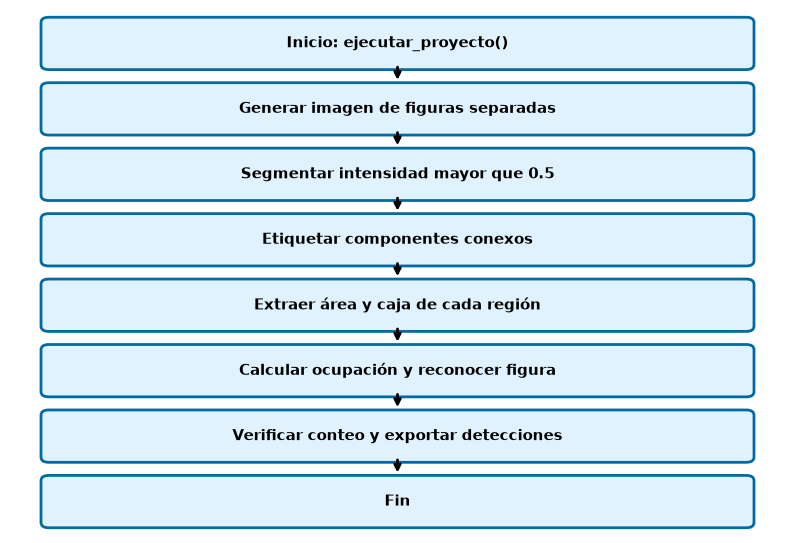

In [2]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
from matplotlib.patches import FancyBboxPatch
pasos=['Inicio: ejecutar_proyecto()', 'Generar imagen de figuras separadas', 'Segmentar intensidad mayor que 0.5', 'Etiquetar componentes conexos', 'Extraer área y caja de cada región', 'Calcular ocupación y reconocer figura', 'Verificar conteo y exportar detecciones', 'Fin']
fig,ax=plt.subplots(figsize=(10,len(pasos)*.85)); ax.set(xlim=(0,10),ylim=(0,len(pasos)*1.25)); ax.axis('off')
for i,paso in enumerate(pasos):
    y=(len(pasos)-i-1)*1.25+.2
    ax.add_patch(FancyBboxPatch((.5,y),9,.8,boxstyle='round,pad=.1',facecolor='#e0f2fe',edgecolor='#0369a1',linewidth=2))
    ax.text(5,y+.4,paso,ha='center',va='center',fontsize=11,fontweight='bold')
    if i<len(pasos)-1:ax.annotate('',xy=(5,y-.35),xytext=(5,y),arrowprops={'arrowstyle':'->','lw':2})
plt.savefig('resultados/diagrama_flujo.png',dpi=140,bbox_inches='tight'); plt.show()


## Implementación y resultados
Las salidas siguientes proceden de ejecutar este código.

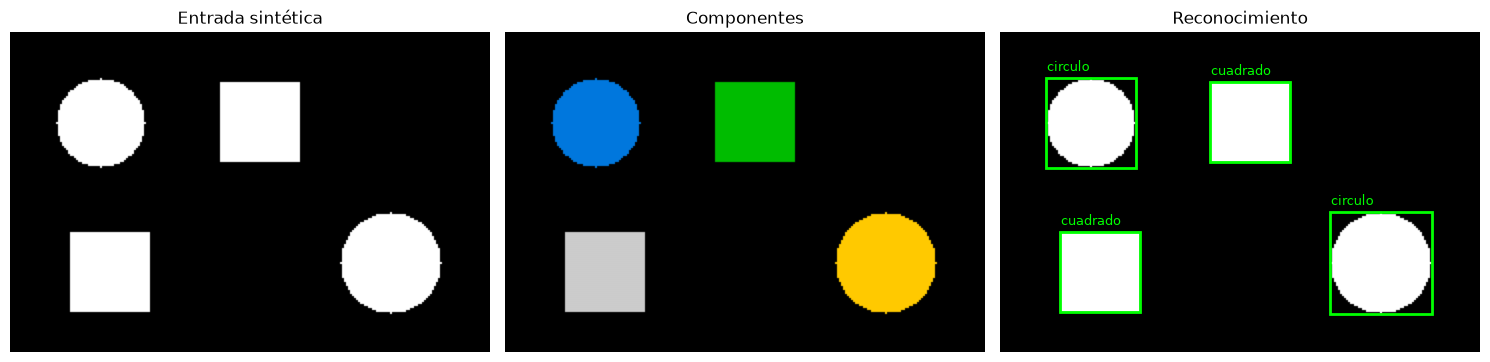

[
  {
    "id": 1,
    "clase": "circulo",
    "x": 23,
    "y": 23,
    "ancho": 45,
    "alto": 45,
    "area": 1517,
    "ocupacion": 0.7491358024691358
  },
  {
    "id": 2,
    "clase": "cuadrado",
    "x": 105,
    "y": 25,
    "ancho": 40,
    "alto": 40,
    "area": 1600,
    "ocupacion": 1.0
  },
  {
    "id": 3,
    "clase": "circulo",
    "x": 165,
    "y": 90,
    "ancho": 51,
    "alto": 51,
    "area": 1961,
    "ocupacion": 0.7539407920030757
  },
  {
    "id": 4,
    "clase": "cuadrado",
    "x": 30,
    "y": 100,
    "ancho": 40,
    "alto": 40,
    "area": 1600,
    "ocupacion": 1.0
  }
]


### Interpretación de la ejecución
Se detectaron **4 figuras**, dos de cada clase, en coincidencia con la escena construida. Esta comprobación verifica el caso controlado; no mide precisión en fotografías independientes.

786

In [3]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
Path('resultados').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False})
from scipy import ndimage
from matplotlib.patches import Rectangle

def ejecutar_proyecto():
    yy,xx=np.mgrid[:160,:240]; image=np.zeros((160,240))
    image[(xx-45)**2+(yy-45)**2<=22**2]=1; image[25:65,105:145]=1
    image[(xx-190)**2+(yy-115)**2<=25**2]=1; image[100:140,30:70]=1
    plt.imsave('imagen_entrada.png',image,cmap='gray',vmin=0,vmax=1)
    labels,total=ndimage.label(image>.5); detections=[]
    fig,ax=plt.subplots(1,3,figsize=(15,4)); ax[0].imshow(image,cmap='gray'); ax[0].set_title('Entrada sintética'); ax[1].imshow(labels,cmap='nipy_spectral'); ax[1].set_title('Componentes'); ax[2].imshow(image,cmap='gray'); ax[2].set_title('Reconocimiento')
    for i,(sy,sx) in enumerate(ndimage.find_objects(labels),1):
        area=int((labels[sy,sx]==i).sum()); h=sy.stop-sy.start; w=sx.stop-sx.start; ratio=area/(h*w)
        kind='cuadrado' if ratio>.88 else 'circulo'
        detections.append({'id':i,'clase':kind,'x':sx.start,'y':sy.start,'ancho':w,'alto':h,'area':area,'ocupacion':ratio})
        ax[2].add_patch(Rectangle((sx.start-.5,sy.start-.5),w,h,fill=False,edgecolor='lime',linewidth=2)); ax[2].text(sx.start,sy.start-4,kind,color='lime',fontsize=9,bbox={'facecolor':'black','pad':1})
    for a in ax:a.axis('off')
    plt.tight_layout(); plt.savefig('resultados/proyecto.png',dpi=140); plt.show()
    counts={k:sum(d['clase']==k for d in detections) for k in ['circulo','cuadrado']}
    assert total==4 and counts=={'circulo':2,'cuadrado':2}
    print(json.dumps(detections,indent=2))
    display(Markdown(f"### Interpretación de la ejecución\nSe detectaron **{total} figuras**, dos de cada clase, en coincidencia con la escena construida. Esta comprobación verifica el caso controlado; no mide precisión en fotografías independientes."))
    return {'total':int(total),'conteos':counts,'detecciones':detections}

metricas=ejecutar_proyecto()
Path('resultados/metricas.json').write_text(json.dumps(metricas,indent=2),encoding='utf-8')


## Conclusiones, limitaciones y exploración
Segmentación produce máscaras; detección localiza; reconocimiento asigna clases. El método resuelve una escena controlada. Figuras tocándose se fusionan y cambios de ruido, iluminación o rotación afectan la regla. En escenas reales se necesitan datos etiquetados y métricas como IoU, precisión, exhaustividad y mAP. Explorar: unir dos figuras o rotar un cuadrado y explicar los errores.

## Referencias oficiales
- https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.label.html
- https://www.tensorflow.org/tutorials/images/classification